# Horizon Forecaster — weekly example

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Lifesight-Software-Pvt-Ltd/horizon/blob/main/examples/weekly_marketing_mix.ipynb)

A complete weekly run on marketing-mix data: turn a sales panel into one weekly series, evaluate
five forecasting models on it, combine them, forecast a quarter ahead against a media plan, and
export the results.

**What this notebook shows**

- preparing a raw panel (week × region × product) into the single tidy series the library expects
- the weekly defaults for the three-way train / validation / test split
- several combination rules built side by side, compared against the best single model
- forecasting against a **media plan you supply**, while the library generates the seasonal drivers
  you do not plan, using the `seasonal_naive` strategy
- the chart and CSV outputs

The daily counterpart in this folder covers the same API on a daily series; this one is about the
weekly defaults and planned drivers.

---

### Dataset

**MMM Weekly Data - Geo:India**, by Kaggle user `subhagatoadak`, licensed **Apache 2.0**.
Source: https://www.kaggle.com/datasets/subhagatoadak/mmm-weekly-data-geoindia

The CSV in `examples/data/` is the file exactly as downloaded — no columns removed, no values changed.
Every bit of preparation happens in this notebook, in the open, so you can disagree with any of it.
11,232 rows: 156 weeks × 8 regions × 9 products (3 brands × 3 SKUs), 2022-07-04 to 2025-06-23.

**This is synthetic data**, generated by its author to train marketing-mix models (media with adstock
and saturation, promotions, pricing, distribution, festive and monsoon seasonality). That suits this
notebook: its job is to show how the library works end to end on an external dataset, not to make
claims about any real brand's sales.

## Before you run

**This notebook fits real models.** The saved outputs come from the full five-model run
(`FAST = False` in §2), which takes considerably longer on a free Colab CPU, because Bayesian PyMC draws
a full MCMC sample per grid candidate. Set `FAST = True` for a three-model run that takes a few minutes.
Prophet and PyMC also compile on first use.

**On Colab specifically:** the default runtime is Python 3.13, and `neuralprophet` pins `numpy<2`,
which publishes no 3.13 wheel — so pip compiles numpy from source and the install takes several extra minutes.
To skip that, set **Runtime → Change runtime type → Runtime version → 2026.07** (Python 3.12) before running.
See [`docs/installation.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/installation.md) for the full explanation.

In [1]:
# Installing from the repository. Once the package is on PyPI this becomes:
#     %pip install -q horizon_forecaster
%pip install -q "git+https://github.com/Lifesight-Software-Pvt-Ltd/horizon.git"

Colab's default runtime has `numpy 2.x` already loaded before you run anything. Horizon pins
`numpy==1.26.4`, because NeuralProphet requires `numpy<2`; the install above downgrades it, but Python
cannot swap a C-extension library like numpy inside a running session. Without a restart, the next cell
fails with `ValueError: numpy.dtype size changed, may indicate binary incompatibility`.
The install may also end with a red `ERROR: pip's dependency resolver ...` list: packages Colab
preinstalls (`jax`, `opencv`, `shap` and others) want `numpy>=2` or another `pandas` version. This
notebook does not import them, and the run is unaffected.

**Run the cell below.** On Colab, when the loaded numpy differs from the installed one, it restarts the
session: Colab disconnects and reconnects in a few seconds (expected, not an error). It does nothing
otherwise — after the restart, or when running locally — so *Run all* is safe to repeat.

**After it reconnects, do not re-run the install cell.** Continue from the next cell: installed packages
persist across a restart within the same session.

In [ ]:
# Restart once on Colab if the numpy in memory is not the one just installed.
# Colab notices the stopped process and starts a fresh one. No-op otherwise,
# including after the restart and outside Colab.
import importlib.metadata
import os
import sys

loaded = sys.modules.get('numpy')
if 'google.colab' in sys.modules and loaded is not None \
        and loaded.__version__ != importlib.metadata.version('numpy'):
    os.kill(os.getpid(), 9)

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from horizon_forecaster import HorizonForecaster, __version__
from horizon_forecaster.exporters import export_forecast
from horizon_forecaster.plotting import (
    plot_evaluation,
    plot_evaluation_per_model,
    plot_forecast,
    plot_model_comparison,
)

print('horizon_forecaster', __version__)

# Warnings are part of the library's output -- it warns about auto-generated
# drivers, over-long horizons and implausible forecasts. Keep them visible.
warnings.simplefilter('always', UserWarning)

horizon_forecaster 1.0.0


## 1. The data

Loaded straight from the repository, so this runs in Colab with nothing to download by hand.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/Lifesight-Software-Pvt-Ltd/horizon/main/examples/data/synthetic_mmm_weekly_india.csv"

raw = pd.read_csv(DATA_URL)
print(raw.shape)
raw.head()

(11232, 28)


,Week,Geo,Brand,SKU,Sales_Units,Sales_Value,MRP,Net_Price,Feature_Flag,Display_Flag,...,FB_Banner_Content_Score,IG_Banner_Content_Score,Weighted_Distribution,Numeric_Distribution,TDP,NOS,CPI,GDP_Growth,Festival_Index,Rainfall_Index
0,2022-07-04,CENTRAL,BrandA,BrandA_SKU1,106.327944,10551.108260,99.231753,99.231753,0,0,...,74.714021,77.999979,0.326712,0.406848,36.923185,3.071753,120.954667,5.24444,1.180806,5.37845
1,2022-07-04,CENTRAL,BrandA,BrandA_SKU2,188.503304,19452.418311,103.194045,103.194045,0,0,...,74.714021,77.999979,0.326712,0.406848,36.923185,3.071753,120.954667,5.24444,1.180806,5.37845
2,2022-07-04,CENTRAL,BrandA,BrandA_SKU3,209.247921,19583.201537,93.588512,93.588512,0,0,...,74.714021,77.999979,0.326712,0.406848,36.923185,3.071753,120.954667,5.24444,1.180806,5.37845
3,2022-07-04,CENTRAL,BrandB,BrandB_SKU1,237.698249,19374.506591,81.508832,81.508832,0,0,...,74.714021,77.999979,0.326712,0.406848,36.923185,3.071753,120.954667,5.24444,1.180806,5.37845
4,2022-07-04,CENTRAL,BrandB,BrandB_SKU2,203.075116,14667.008092,72.224546,72.224546,0,0,...,74.714021,77.999979,0.326712,0.406848,36.923185,3.071753,120.954667,5.24444,1.180806,5.37845


In [3]:
# A panel, not a series: one row per week x region x product.
print('weeks    :', raw['Week'].nunique(), f"({raw['Week'].min()} to {raw['Week'].max()})")
print('regions  :', raw['Geo'].nunique(), sorted(raw['Geo'].unique()))
print('products :', raw['SKU'].nunique(), 'across', raw['Brand'].nunique(), 'brands')
print('missing  :', int(raw.isna().sum().sum()))

weeks    : 156 (2022-07-04 to 2025-06-23)
regions  : 8 ['CENTRAL', 'EAST', 'METRO_DELHI', 'METRO_MUMBAI', 'NORTH', 'NORTHEAST', 'SOUTH', 'WEST']
products : 9 across 3 brands
missing  : 0


### Preparing it

Horizon forecasts **one series**: a date column, a numeric target, and optional driver columns, one row
per week. So the panel is totalled to national weekly figures. How each column is totalled depends on
the level it is recorded at, which the next cell checks rather than assumes:

| Column | Recorded per | Becomes | Why |
|---|---|---|---|
| `Sales_Value` | week × region × product | **sum** → `sales_value` (the target) | total national revenue |
| TV, YouTube, Facebook, Print, Radio | week × region × product | **sum** → five media columns | each product's share of the media weight; summing gives the national total |
| `Trade_Spend` | week × region (repeated on each product row) | one value per region, then **sum** | summing every row would count it nine times |
| `Festival_Index`, `Rainfall_Index` | week × region | **mean** across regions | they are indices, so an average is the meaningful national figure |

Left out on purpose:

- `Instagram_Impressions` — the dataset's own documentation says it is derived from YouTube and
  Facebook, so it would only duplicate them.
- `CPI` and `GDP_Growth` — macro series that trend with sales over the whole period. A model would read
  the shared trend as an effect, and you would also have to guess their future values.
- the promotion flags, prices, distribution and creative scores — real drivers in this dataset, but
  dropped to keep the example readable. Trade spend is set from promotion intensity, so it carries
  most of the promotion signal.

`Week` is parsed to a date; it is already one row per week with no gaps, which the checks confirm.
Nothing is filled, imputed or dropped — the library requires complete data and raises
`InvalidConfigError` on a single missing cell rather than guessing.

In [4]:
# Check, don't assume: how many distinct values does each column take within one week x region?
# 1 means it is recorded per region (repeated on every product row); 9 means per product.
per_region = raw.groupby(['Week', 'Geo']).nunique().max()
print(per_region[['Sales_Value', 'TV_Impressions', 'Trade_Spend', 'Festival_Index', 'Rainfall_Index']])

Sales_Value       9
TV_Impressions    9
Trade_Spend       1
Festival_Index    1
Rainfall_Index    1
dtype: int64


In [5]:
MEDIA = {
    'TV_Impressions': 'tv_impressions',
    'YouTube_Impressions': 'youtube_impressions',
    'Facebook_Impressions': 'facebook_impressions',
    'Print_Readership': 'print_readership',
    'Radio_Listenership': 'radio_listenership',
}

data = raw.assign(Week=pd.to_datetime(raw['Week']))

# Recorded per product row: sum straight across the panel.
product_level = (
    data.groupby('Week')[['Sales_Value', *MEDIA]].sum()
        .rename(columns={'Sales_Value': 'sales_value', **MEDIA})
)

# Recorded per region: take each region's value once, then combine across regions.
region_level = (
    data.groupby(['Week', 'Geo'])[['Trade_Spend', 'Festival_Index', 'Rainfall_Index']].first()
        .groupby('Week')
        .agg(trade_spend=('Trade_Spend', 'sum'),
             festival_index=('Festival_Index', 'mean'),
             rainfall_index=('Rainfall_Index', 'mean'))
)

df = (
    product_level.join(region_level)
        .reset_index()
        .rename(columns={'Week': 'date'})
        .sort_values('date')
        .reset_index(drop=True)
)

# The three things the library cares about before it will take the frame.
print('rows             :', len(df))
print('missing cells    :', int(df.isna().sum().sum()))
print('duplicate dates  :', int(df['date'].duplicated().sum()))
print('week gaps (days) :', sorted(df['date'].diff().dt.days.dropna().unique()))
df.head()

rows             : 156
missing cells    : 0
duplicate dates  : 0
week gaps (days) : [7.0]


,date,sales_value,tv_impressions,youtube_impressions,facebook_impressions,print_readership,radio_listenership,trade_spend,festival_index,rainfall_index
0,2022-07-04,1.010975e+06,5.021806e+07,2.482167e+07,1.350719e+07,4.715606e+06,4.664091e+07,114000.084242,0.967491,4.615099
1,2022-07-11,1.330988e+06,4.894350e+07,2.352123e+07,1.181995e+07,4.646868e+06,4.473567e+07,569943.875951,0.967491,4.192446
2,2022-07-18,1.570576e+06,4.864866e+07,2.177846e+07,1.336336e+07,4.693193e+06,4.735607e+07,687561.586822,0.967491,3.686839
3,2022-07-25,1.315034e+06,4.976261e+07,2.492207e+07,1.406158e+07,4.714154e+06,4.340736e+07,82623.004056,0.967491,4.247928
4,2022-08-01,1.344600e+06,5.135814e+07,2.438089e+07,1.348533e+07,4.439110e+06,4.830241e+07,86857.645702,0.967491,3.752615


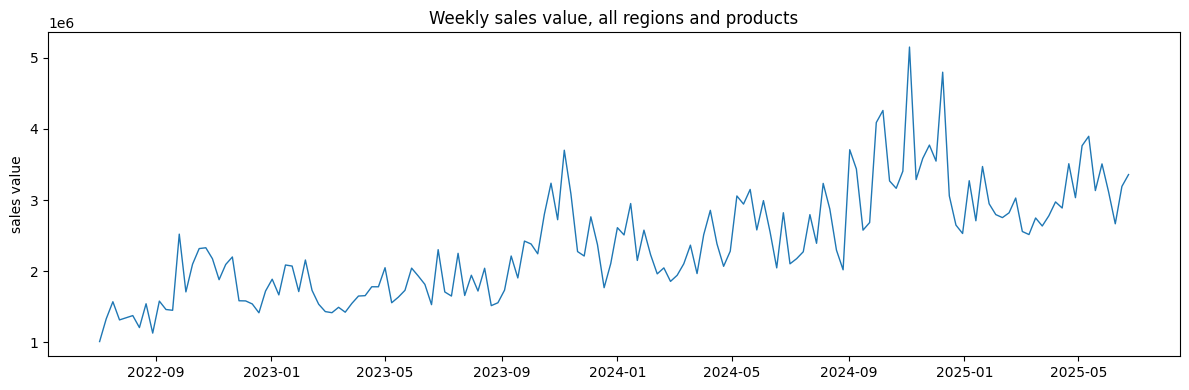

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df['date'], df['sales_value'], linewidth=1)
ax.set_title('Weekly sales value, all regions and products')
ax.set_ylabel('sales value')
fig.tight_layout()
plt.show()

In [7]:
# How strongly each driver moves with sales, before any modelling.
df.drop(columns='date').corr()['sales_value'].drop('sales_value').round(2).sort_values()

,sales_value
radio_listenership,-0.26
rainfall_index,-0.22
youtube_impressions,0.04
facebook_impressions,0.20
tv_impressions,0.24
print_readership,0.24
festival_index,0.25
trade_spend,0.59


Three years of weekly sales with growth, a festive-season lift each autumn, and promotion spikes.

Read the correlations above with care: they are same-week and one at a time. Media in this dataset
works through adstock (its effect carries into later weeks) and saturation, and the channels are
scheduled together, so a weak same-week correlation does not mean a channel does nothing. Trade spend
moves most closely with sales week to week, which is what promotion-driven sales look like.

## 2. Constructing the forecaster

Weekly data uses its own defaults for the split: **39 weeks** of validation and **13 weeks** of test,
leaving 104 weeks to train on.

`future_exog_strategy='seasonal_naive'` matters later, in §5: any driver you do not supply for the
forecast period is filled with its typical value for that week of the year, averaged over the
history, plus the driver's trend. That is the right assumption for the festival and monsoon
indices, which follow the calendar.

In [8]:
TARGET  = 'sales_value'
MEDIA_COLUMNS = list(MEDIA.values())
DRIVERS = MEDIA_COLUMNS + ['trade_spend', 'festival_index', 'rainfall_index']

# All five models, each fully grid-searched -- this is the run the saved outputs show.
# Set FAST = True for three models in a few minutes; see the note at the top about runtime.
FAST = False
MODELS = ['prophet', 'catboost', 'sarimax'] if FAST else None   # None = every registered model

forecaster = HorizonForecaster(
    df,
    date_column='date',
    target_column=TARGET,
    frequency='weekly',
    independent_columns=DRIVERS,
    validation_size=None,      # None -> 39 periods for weekly. Every DECISION is scored here.
    test_size=None,            # None -> 13 periods for weekly. REPORTED, never selected on.
    models=MODELS,
    mape_threshold=40.0,       # degenerate-fit filter on the validation MAPE; None admits everything
    ensemble_method=None,      # None -> build all three rules: trimmed, inverse_mape, equal
    future_exog_strategy='seasonal_naive',
)

print('models      :', MODELS or 'all registered')
print('ensembles   :', forecaster.ensemble_methods)

models      : all registered
ensembles   : ['trimmed', 'inverse_mape', 'equal']


## 3. Evaluate

`evaluate()` splits the series chronologically into **train / validation / test**, grid-searches each
model's hyperparameters on the validation window, refits the winner on train + validation, and scores
it once on the test window — which no selection path is ever allowed to read.

| field | window | meaning |
|---|---|---|
| `validation_mape` | validation | the score every decision was made on. Optimistic by construction — candidates were chosen to minimise it. |
| `mape` | test | the score reported. The honest out-of-sample number. |
| `validation_wape`, `wape` | validation, test | the same two windows as WAPE, which also counts the days whose actual is 0. When `forecaster.selection_metric` is `'wape'` (a target with many zeros, or one that goes negative), the decisions were made on `validation_wape`. |

With weekly data the test window is a single quarter, so one unusual week moves the score noticeably.

Expect a SARIMAX warning from the next cell. Most drivers here follow the yearly cycle (media is
flighted around the festive season, rainfall follows the monsoon), so they overlap with SARIMAX's own
yearly seasonal terms. The library flags this and lets the grid search pick a setting that copes;
nothing has failed.

In [9]:
%%time
results = forecaster.evaluate()

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
/usr/local/lib/python3.13/dist-packages/horizon_forecaster/forecaster.py:972: UserWarning: SARIMAX: independent column(s) strongly track the annual seasonal cycle: rainfall_index (annual R²=0.62), festival_index (annual R²=0.57), tv_impressions (annual R²=0.53), radio_listenership (annual R²=0.52), facebook_impressions (annual R²=0.48), print_readership (annual R²=0.39), youtube_impressions (annual R²=0.37). These explain much of the same variance as SARIMAX's annual Fourier terms, so on short histories the two compete and the higher fourier_order_annual grid candidates can become unstable (a good low-Fourier fit can collapse once such a column is added). This is expected, not an error -- the grid search will tend to pick a lower Fourier order when these columns are present. If a run w

CPU times: user 8min 36s, sys: 5.93 s, total: 8min 42s
Wall time: 9min 34s


In [10]:
summary = pd.DataFrame([
    {
        'model': name,
        'test MAPE %': round(r.mape.value, 2),
        'validation MAPE %': round(r.validation_mape.value, 2),
        'test WAPE %': round(r.wape, 2),
        'validation WAPE %': round(r.validation_wape, 2),
        'train': r.n_train,
        'validation': r.n_validation,
        'test': r.n_test,
    }
    for name, r in results.items()
]).sort_values('test MAPE %').reset_index(drop=True)

# selection_metric is 'mape' unless the target is 0 on 10% or more of days or goes
# negative; then every decision is made on WAPE instead (with a warning).
print('selection metric:', forecaster.selection_metric)
# The bar to clear: the same weekday last week (daily) or week last year (weekly).
print(f'seasonal naive: test MAPE {forecaster.naive_baseline.mape.value:.2f}%, '
      f'WAPE {forecaster.naive_baseline.wape:.2f}%')
summary

,model,test MAPE %,validation MAPE %,train,validation,test
0,sarimax,4.13,9.02,104,39,13
1,bayesianpymc,4.54,6.85,104,39,13
2,neuralprophet,5.43,6.35,104,39,13
3,prophet,6.09,7.03,104,39,13
4,catboost,9.82,20.93,104,39,13


In [11]:
# Models that failed to fit or predict at all are recorded separately from models
# that fitted but were not admitted to a combination. The two are never conflated.
print('failed to fit :', dict(forecaster.evaluate_errors) or 'none')

failed to fit : none


### The ensembles

All three rules were built from the same fitted models — combination is arithmetic over predictions
already in memory, so asking for every rule costs essentially nothing beyond the first.

In [12]:
rows = []
for method, ens in forecaster.evaluate_ensemble.items():
    rows.append({
        'method': method,
        'rule applied': ens.rule_applied,
        'degraded': ens.degraded,
        'members': len(ens.members),
        'MAPE %': round(ens.mape.value, 2) if ens.mape is not None else None,
        'WAPE %': round(ens.wape, 2) if ens.wape is not None else None,
        'weights': ens.weights,
        'rejected': list(ens.rejected_models) or None,
    })

pd.DataFrame(rows)

,method,rule applied,degraded,members,MAPE %,weights,rejected
0,trimmed,trimmed,False,5,4.61,None,None
1,inverse_mape,inverse_mape,False,5,4.74,"{'prophet': 0.23533120719431413, 'catboost': 0...",None
2,equal,equal,False,5,5.07,"{'prophet': 0.2, 'catboost': 0.2, 'sarimax': 0...",None


**Compare those against the per-model table above before trusting any of them.** A combined forecast is
*not* guaranteed to beat the best single model — which is why the library scores every ensemble against
actuals and the exporter writes both a combined and a best-single-model CSV. The best single model is the one with the lowest *validation* MAPE among the models within `mape_threshold` on both validation and test; `model_summary` says why each model was or was not chosen.

## 4. Charts

`plot_evaluation` returns **one chart per combination rule**, keyed by method — always a dict, even for
a single rule.

charts returned: ['trimmed', 'inverse_mape', 'equal']


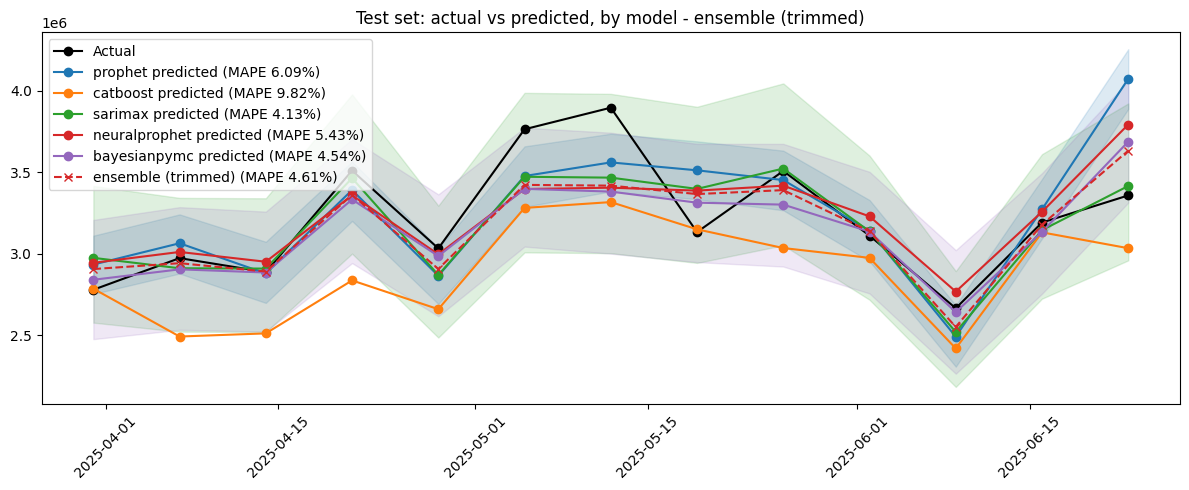

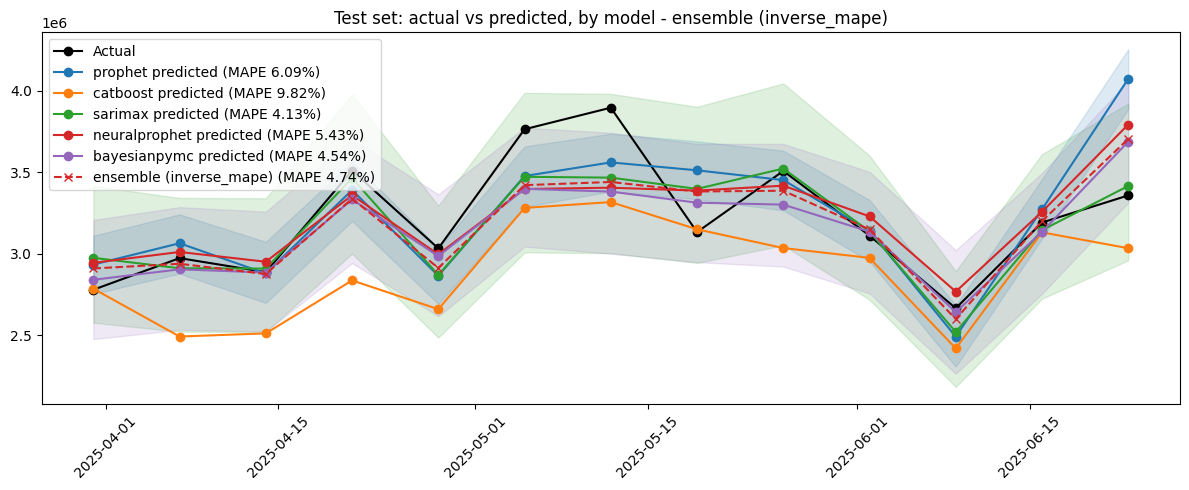

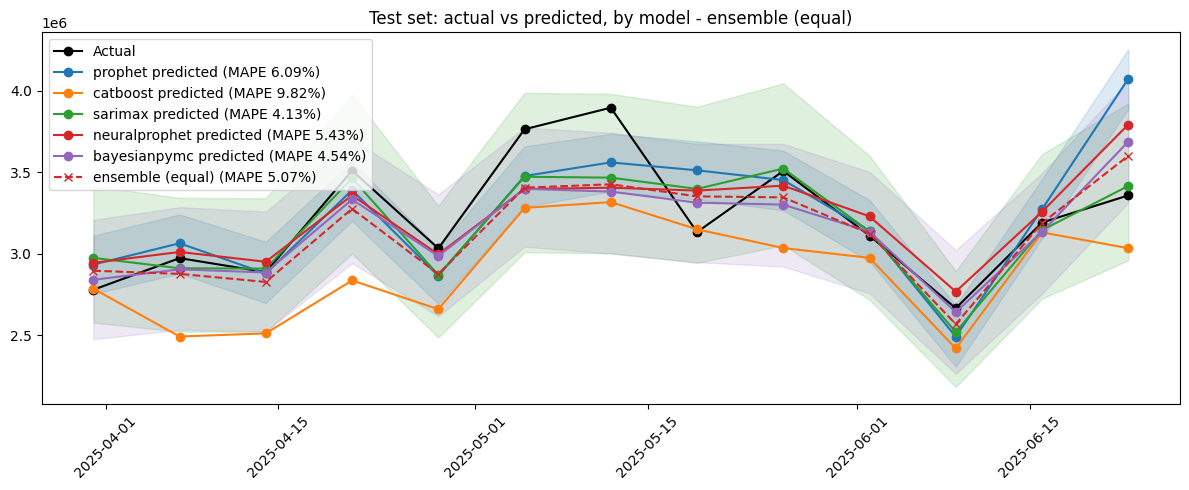

In [13]:
axes = plot_evaluation(results, forecaster.evaluate_ensemble)
print('charts returned:', list(axes))
plt.show()

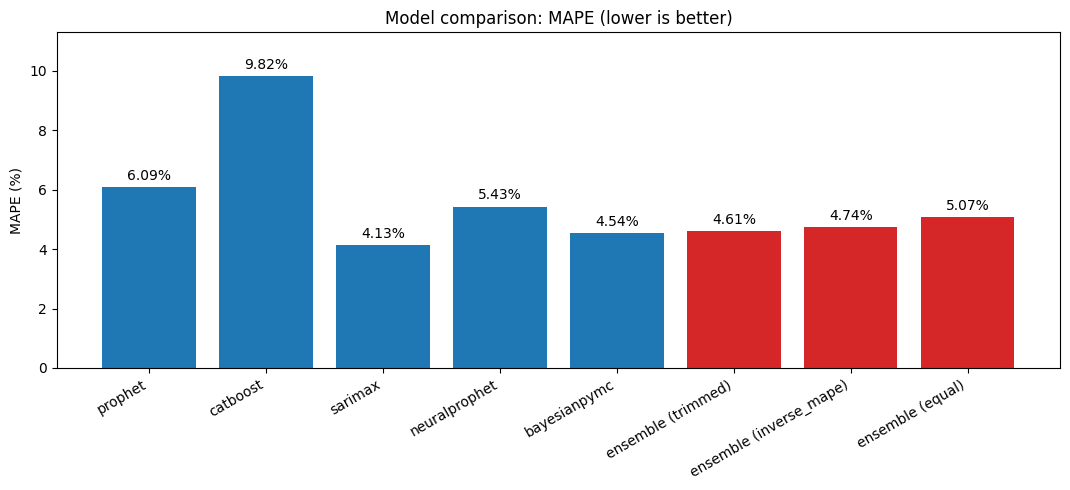

In [14]:
# Every rule on one axes. These bars are TEST-window scores; grey is the seasonal-naive baseline.
plot_model_comparison(results, forecaster.evaluate_ensemble,
                      metric=forecaster.selection_metric, baseline=forecaster.naive_baseline)
plt.show()

figures: ['prophet', 'catboost', 'sarimax', 'neuralprophet', 'bayesianpymc', 'ensemble_trimmed', 'ensemble_inverse_mape', 'ensemble_equal']


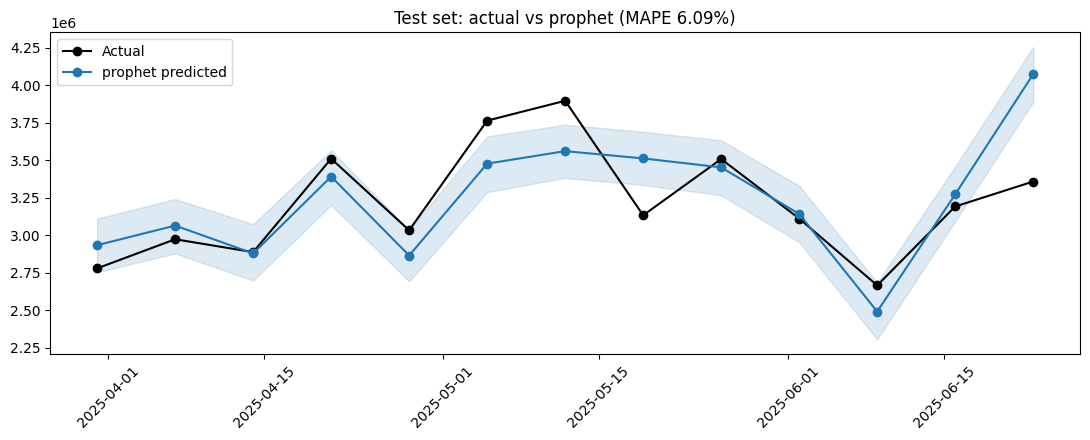

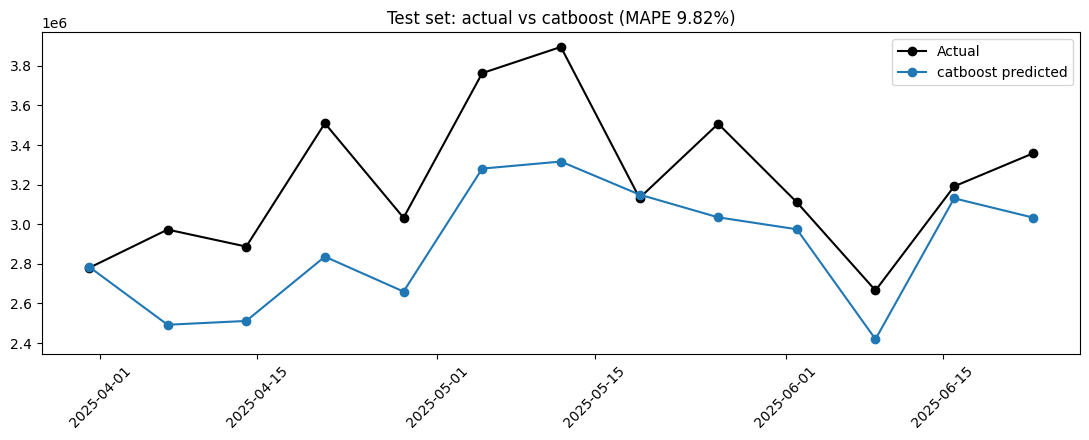

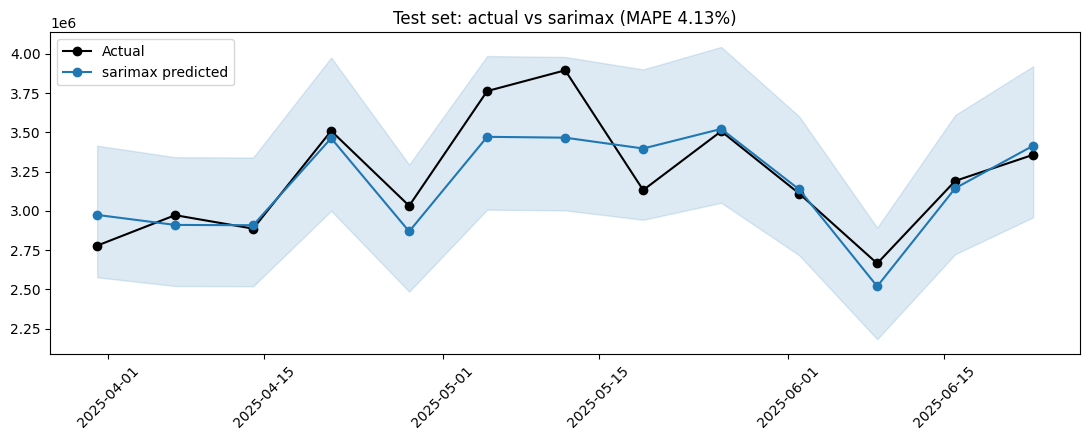

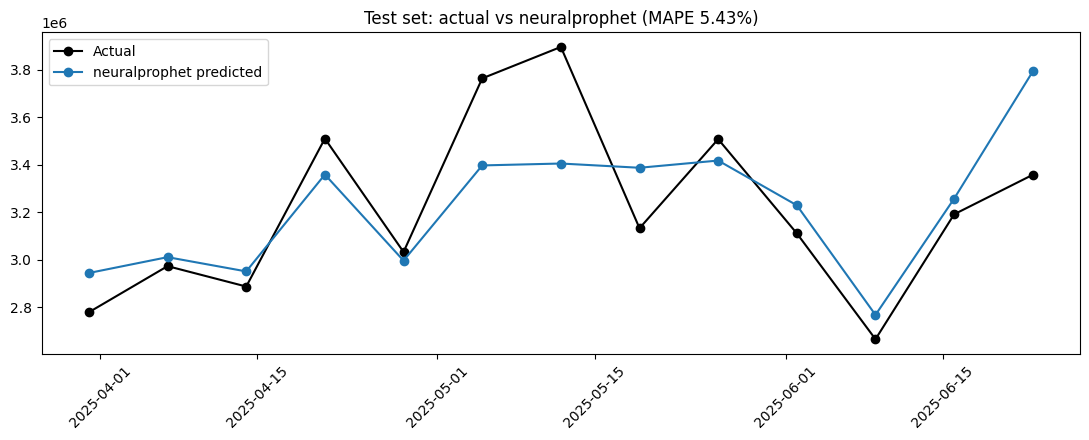

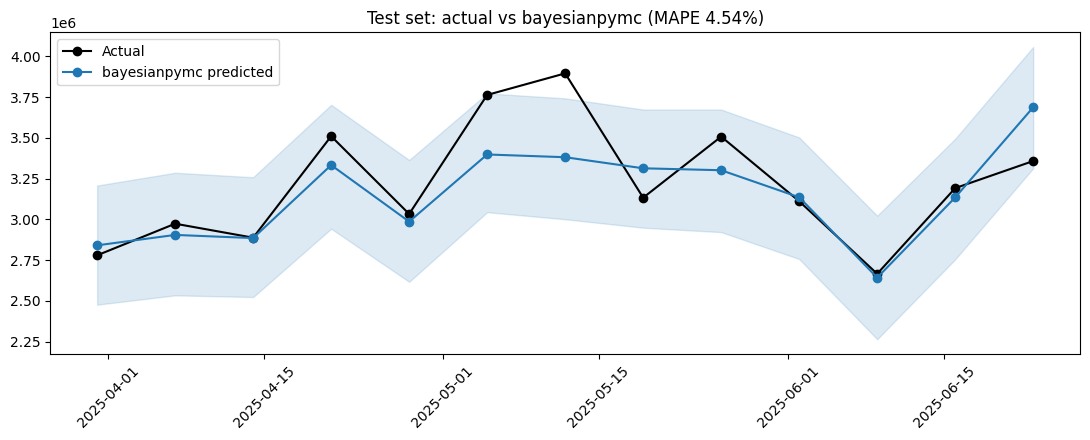

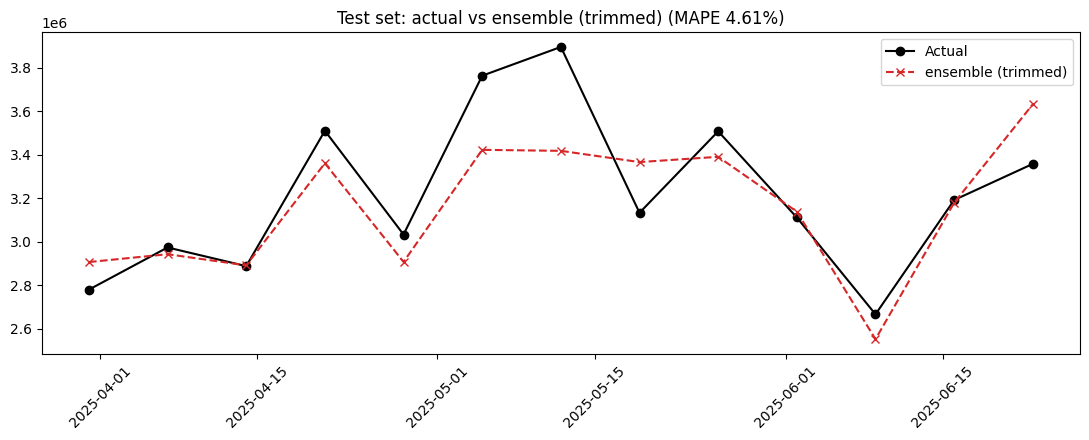

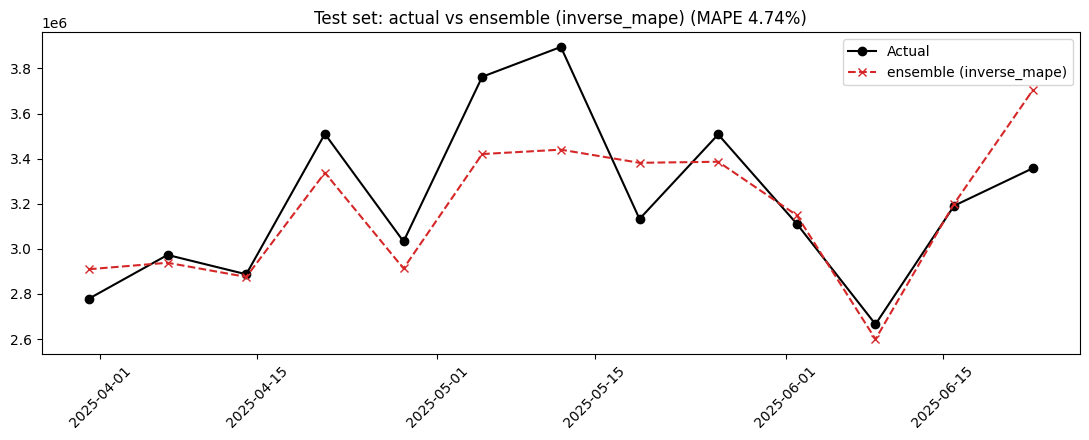

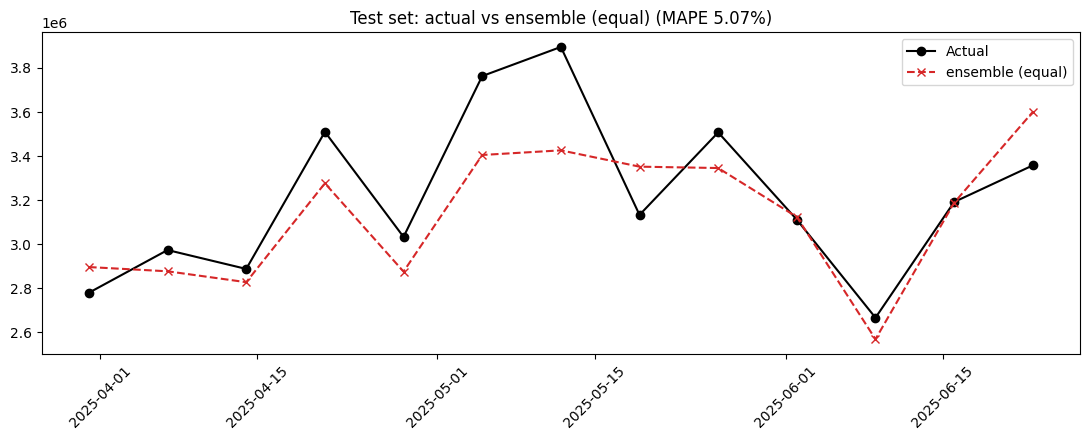

In [15]:
# One full-size figure per model, plus one per rule that formed.
figures = plot_evaluation_per_model(results, forecaster.evaluate_ensemble)
print('figures:', list(figures))
plt.show()

## 5. Forecasting a quarter against a media plan

This is the question a marketing team actually asks: *if we run this plan next quarter, what do sales
look like?* The drivers split cleanly into two kinds:

- **Planned** — media weight and trade spend are decisions, so you supply them. Here the plan simply
  repeats the last 13 weeks; in a real run you would put your actual media plan in this frame.
- **Seasonal** — the festival and monsoon indices follow the calendar, not a plan. They are left out,
  and the library fills them with `seasonal_naive` (that week of the year's typical value, plus trend) — and warns that it did.

Supplying some columns and leaving others out is **partial fill**: a supplied column is used as-is and
only the missing ones are generated. The plan also carries a `date` column, which the library checks against
the forecast dates, so a plan that starts a week late or skips a week is refused rather than misapplied.

In [16]:
HORIZON = 13   # one quarter of weeks

future_dates = pd.date_range(
    start=df['date'].max() + pd.Timedelta(weeks=1), periods=HORIZON, freq='7D'
)

# The plan: repeat the last 13 weeks of media and trade spend. Replace with your own plan.
PLANNED = MEDIA_COLUMNS + ['trade_spend']
media_plan = df[PLANNED].tail(HORIZON).reset_index(drop=True)
media_plan.insert(0, 'date', future_dates)   # optional, but checked against the forecast dates when present

print(f'supplying {PLANNED} for {HORIZON} weeks starting {future_dates[0].date()}')
print('festival_index and rainfall_index will be generated (seasonal_naive)')
media_plan.head()

supplying ['tv_impressions', 'youtube_impressions', 'facebook_impressions', 'print_readership', 'radio_listenership', 'trade_spend'] for 13 weeks starting 2025-06-30
festival_index and rainfall_index will be generated (seasonal_naive)


,date,tv_impressions,youtube_impressions,facebook_impressions,print_readership,radio_listenership,trade_spend
0,2025-06-30,5.245485e+07,7.502957e+07,1.289081e+07,4.593808e+06,1.508100e+07,168150.984240
1,2025-07-07,4.466561e+07,8.080448e+07,1.479055e+07,4.535003e+06,1.593448e+07,116249.749519
2,2025-07-14,4.835503e+07,6.659836e+07,1.262567e+07,4.457958e+06,1.371864e+07,99871.561454
3,2025-07-21,5.007460e+07,7.324740e+07,1.273103e+07,4.338906e+06,1.715889e+07,540514.664541
4,2025-07-28,5.092083e+07,6.590059e+07,1.343002e+07,4.593620e+06,1.496684e+07,122074.598887


In [17]:
%%time
forecasts = forecaster.forecast(horizon=HORIZON, future_independent_data=media_plan)
print('failed to forecast:', dict(forecaster.forecast_errors) or 'none')

WARNING - (py.warnings._showwarnmsg) - <timed exec>:1: UserWarning: future values for ['festival_index', 'rainfall_index'] were auto-generated for all 13 periods via the 'seasonal_naive' strategy (no values were supplied for them). The forecast is only as reliable as those assumed inputs -- for an exogenous-variable-driven model this can dominate the result. Supply real planned values if you have them (you can supply just some columns; the rest are filled), inspect what was assumed via forecaster.future_exog_used, and treat this output as a scenario rather than a prediction.


WARNING - (py.warnings._showwarnmsg) - /usr/local/lib/python3.13/dist-packages/horizon_forecaster/forecaster.py:1576: UserWarning: SARIMAX: independent column(s) strongly track the annual seasonal cycle: rainfall_index (annual R²=0.63), festival_index (annual R²=0.56), radio_listenership (annual R²=0.53), tv_impressions (annual R²=0.53), facebook_impressions (annual R²=0.46), print_readership (annual R²=0.37), yo

failed to forecast: none
CPU times: user 2min 9s, sys: 508 ms, total: 2min 10s
Wall time: 2min 15s


The warning above names the columns that were generated and the strategy used. You can always inspect
exactly what the forecast was given — supplied and generated columns together:

In [18]:
forecaster.future_exog_used.head()

,ds,tv_impressions,youtube_impressions,facebook_impressions,print_readership,radio_listenership,trade_spend,festival_index,rainfall_index
0,2025-06-30,5.245485e+07,7.502957e+07,1.289081e+07,4.593808e+06,1.508100e+07,168150.984240,0.702231,3.723282
1,2025-07-07,4.466561e+07,8.080448e+07,1.479055e+07,4.535003e+06,1.593448e+07,116249.749519,0.702231,4.008012
2,2025-07-14,4.835503e+07,6.659836e+07,1.262567e+07,4.457958e+06,1.371864e+07,99871.561454,0.702231,3.185270
3,2025-07-21,5.007460e+07,7.324740e+07,1.273103e+07,4.338906e+06,1.715889e+07,540514.664541,0.702231,3.653832
4,2025-07-28,5.092083e+07,6.590059e+07,1.343002e+07,4.593620e+06,1.496684e+07,122074.598887,0.702231,3.548470


charts returned: ['trimmed', 'inverse_mape', 'equal']


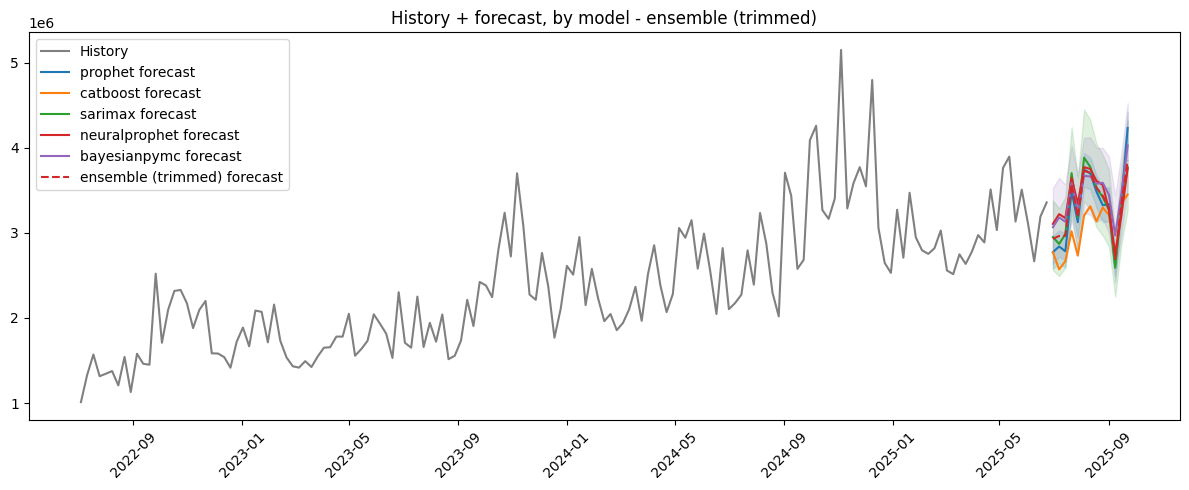

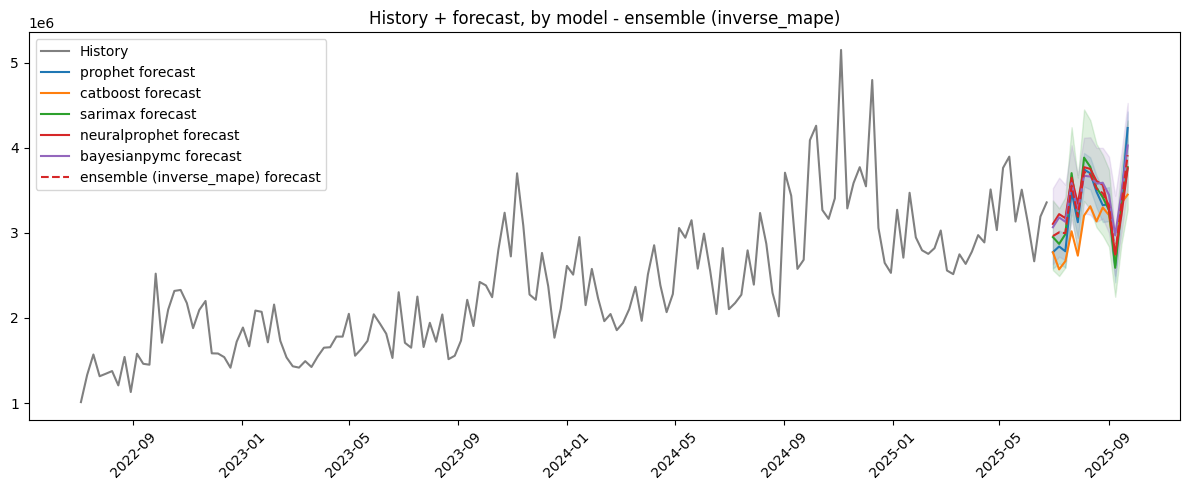

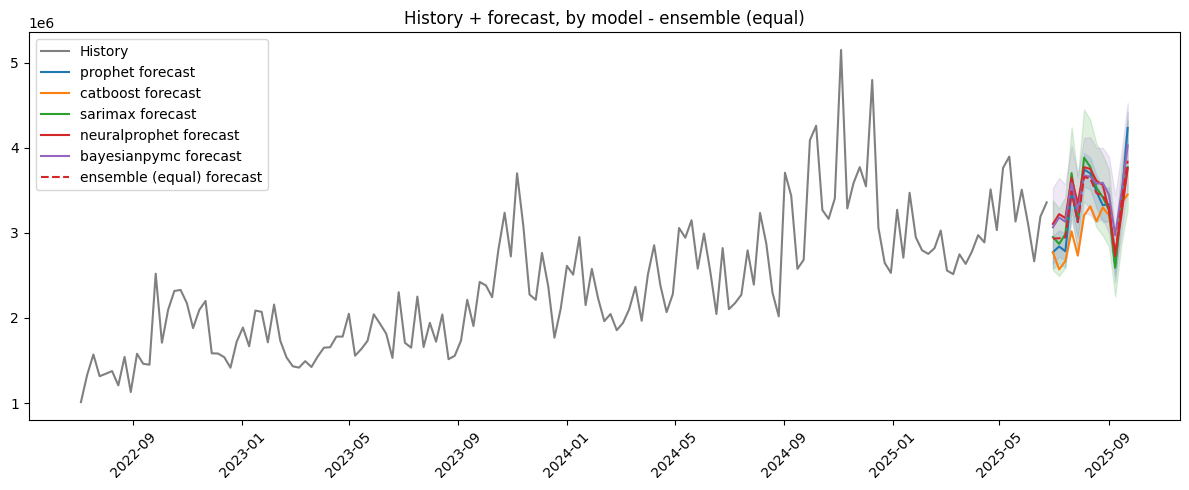

In [19]:
forecast_axes = plot_forecast(
    forecasts,
    history=df,
    date_column='date',
    target_column=TARGET,
    ensemble=forecaster.forecast_ensemble,
)
print('charts returned:', list(forecast_axes))
plt.show()

To compare plans, change `media_plan` — say, double the YouTube weight in the first four weeks — and run
the forecast cell again. The full-data fit is cached after the first `forecast()` call, so trying another
plan only re-runs prediction: no new grid search and no refit.

## 6. Export

One call writes the CSVs and the charts into a single folder.

In [20]:
paths = export_forecast(
    forecasts,
    forecaster=forecaster,     # fills in the ensembles, every score, the threshold and the baseline
    history=df,
    date_column='date',
    target_column=TARGET,
    output_dir='output',
    prefix='weekly',
    save_plots=True,
)

for key in sorted(paths):
    print(f'{key:34s} {paths[key]}')

final_best_model                   output/weekly_final_best_model.csv
final_ensemble_equal               output/weekly_final_ensemble_equal.csv
final_ensemble_inverse_mape        output/weekly_final_ensemble_inverse_mape.csv
final_ensemble_trimmed             output/weekly_final_ensemble_trimmed.csv
model_summary                      output/weekly_model_summary.csv
per_model                          output/weekly_per_model.csv
plot_bayesianpymc                  output/weekly_bayesianpymc.png
plot_catboost                      output/weekly_catboost.png
plot_ensemble_equal                output/weekly_ensemble_equal.png
plot_ensemble_inverse_mape         output/weekly_ensemble_inverse_mape.png
plot_ensemble_trimmed              output/weekly_ensemble_trimmed.png
plot_neuralprophet                 output/weekly_neuralprophet.png
plot_overlay_equal                 output/weekly_overlay_equal.png
plot_overlay_inverse_mape          output/weekly_overlay_inverse_mape.png
plot_overlay_trimmed

In [21]:
pd.read_csv(paths['model_summary'])

,model,validation_mape,mape,ensemble_method,rule_applied,ensemble_weight,status,best_model_check
0,prophet,7.030967,6.085149,trimmed,trimmed,NaN,in_ensemble,passed
1,catboost,20.931799,9.824082,trimmed,trimmed,NaN,in_ensemble,passed
2,sarimax,9.021415,4.131280,trimmed,trimmed,NaN,in_ensemble,passed
3,neuralprophet,6.345334,5.429759,trimmed,trimmed,NaN,in_ensemble,exported as best: lowest validation MAPE among...
4,bayesianpymc,6.852700,4.539344,trimmed,trimmed,NaN,in_ensemble,passed
5,ensemble,NaN,NaN,trimmed,trimmed,1.000000,ensemble,NaN
6,prophet,7.030967,6.085149,inverse_mape,inverse_mape,0.235331,in_ensemble,passed
7,catboost,20.931799,9.824082,inverse_mape,inverse_mape,0.079047,in_ensemble,passed
8,sarimax,9.021415,4.131280,inverse_mape,inverse_mape,0.183409,in_ensemble,passed
9,neuralprophet,6.345334,5.429759,inverse_mape,inverse_mape,0.260759,in_ensemble,exported as best: lowest validation MAPE among...


## Where to go next

- [`docs/quickstart.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/quickstart.md) — the full API walkthrough
- [`docs/supported_models.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/supported_models.md) — what each model does, and its caveats
- [`docs/ensemble_methods.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/ensemble_methods.md) — the combination rules in detail
- [`docs/future_exog.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/future_exog.md) — the future-driver strategies, including `seasonal_naive`
- [`docs/design_notes.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/design_notes.md) — why the library is built this way

**Two honest caveats about this example.**

Every score here comes from a single 13-week test window, so it reflects one quarter rather than an
average over several origins — rolling-origin backtesting is a known gap, listed in the changelog.
And the data is synthetic, generated to have the structure marketing-mix models look for, so treat the
numbers as a demonstration that the machinery works, not as evidence about how well these models
forecast your series. Horizon forecasts sales from drivers; it does not estimate channel ROI, which is
what a marketing-mix model is for.